# 01 – Data Source Layer

**Projekt:** Wohnungsmarkt-Radar Wien – Preis/Leistungs-Score für Mietwohnungen

**Layer:** Data Source Layer - Identifikation der Datenquellen & Methoden der Datengewinnung

**Beschreibung:** Dieses Notebook beschreibt, woher die Daten kommen und wie sie gewonnen werden. Es beschreibt die Webscraper, zeigt Beispiele der Rohdaten und gibt einen Überblick über Umfang und Qualität der Daten

**Fragestellung:** 
Ist eine Mietwohnung für den Bezirk preislich günstig, normal oder teuer? Dafür bilden wir einen Preis/Leistungsscore pro Wohnung aus Gesamtmiete, Fläche, Zimmeranzahl, Lage und die Anbindung an den öffentlichen Verkehr.

**Überblick der Quellen:**

| Quelle | Art | Methode | Format | Koordinaten |
|---|---|---|---|---|
| Willhaben | Web Scraping | HTML abrufen, eingebettetes JSON (`__NEXT_DATA__`) auslesen | JSONL | ja |
| ImmoScout24 | Web Scraping | GraphQL-Schnittstelle der Website (Persisted Query) | JSONL | ja |
| DerStandard Immobilien | Web Scraping | HTML abrufen, Karten und eingebettetes JSON auslesen | JSONL | nein (Geocoding nötig) |
| Wiener Linien: Haltestellen | Open Data | Download GeoJSON | GeoJSON | ja |
| Wien: Bezirksgrenzen | Open Data | Download GeoJSON | GeoJSON | ja (EPSG:31256) |
| Nominatim (OpenStreetMap) | Geocoding | Adresse -> Koordinaten, nur für DerStandard | JSON (Cache) | ja |

**Links zu den Quellen:**

•	ImmoScout24: https://www.immobilienscout24.at/portal/graphql

•	Der Standard: https://immobilien.derstandard.at/suche/wien/mieten-wohnung 

•	Willhaben: https://www.willhaben.at/iad/immobilien/mietwohnungen/mietwohnung-angebote?areaId=900

•	Öffentliches Verkehrsnetz Haltestellen Wien: https://www.data.gv.at/datasets/f1f6f15d-2faa-4b62-b78b-80599dd1c66e?locale=de

•	Bezirksgrenzen: https://www.data.gv.at/datasets/2ee6b8bf-6292-413c-bb8b-bd22dbb2ad4b?locale=de





**Gesamtablauf:**
```
Datasources accesed via webscraper:                 Open Data:
 Portale (Willhaben, ImmoScout24, DerStandard)      Open Data (Haltestellen, Bezirke)
              │  Node.js-Scraper (app.js)                        │  Download aus data.gv.at
              ▼                                                  ▼
        data/raw/*.jsonl                                data/external/*.geojson
              │                                                  │
              └──────────────► 02_data_storage ◄─────────────────┘





# 1. Vorbereitung

Pfad definieren, Dateien einlesen und Daten ausgeben

In [4]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

BASE = Path.cwd().parent
RAW = BASE / "data" / "raw"
EXTERNAL = BASE / "data" / "external"


def read_jsonl(path):
    """Liest eine JSONL-Datei (eine JSON-Zeile pro Inserat)."""
    if not path.exists():
        print(f"{path} nicht gefunden – bitte zuerst 'node app.js' ausführen")
        return []
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


willhaben = read_jsonl(RAW / "willhaben_listings.jsonl")
immoscout = read_jsonl(RAW / "immobilienscout_listings.jsonl")
standard = read_jsonl(RAW / "standard_listings.jsonl")
print(f"Willhaben: {len(willhaben)} | ImmoScout24: {len(immoscout)} | DerStandard: {len(standard)} Inserate")

Willhaben: 125 | ImmoScout24: 100 | DerStandard: 76 Inserate


# 2. Webscraping der Portale

Die Scraper sind in JavaScript (Node.js) geschrieben und liegen im Ordner immo_webscraper

app.js <- zentrale Steuerung der einzelnen Scraper mit node app.js
Die Scraper werden nacheinander ausgeführt:
test/willhaben_test.js      <- scrapeWillhaben()
test/immoscout24_test.js    <- scrapeImmoScout()
test/standard_test.js       <- scrapeStandard()

Jeder Scraper wird nacheinander ausgeführt und lässt 3 Sekunden Pause zwischen den Portalseiten, da sonst ein Timeout (zumindest auf Willhaben) kommt, wenn diese zu schnell gescraped werden. Die Daten werden unter data/raw als JSONL gespeichert und nicht verändert. 

**Willhaben Scraper:**
Der Scraper lädt die Suchseite, schneiden den __NEXT_DATA__ -Block aus, parst ihn und wandelt das Attribut-Array jedes Inserats (zB: {name: "PRICE", values: [...]}) in Felder wie price, estate_size ect. um. Auf Willhaben sind coordinates sowie floor vorhanden.

**ImmoScout24 Scraper:**
Die Seite lädt ihre Ergebnisse über eine GraphQL-Schnittstelle (`/portal/graphql`). Der Scraper schickt dieselbe Anfrage wie die Website (Parameter: Miete, Wohnnutzung, Region Wien, Seitengröße, Startindex) und speichert die Treffer. Koordinaten sind vorhanden (`location.lat/lon`), ein Stockwerk nicht konsistent. In der Stichprobe enthielt die Antwort teils Kauf-Inserate und Bauprojekte mit Spannen statt Einzelwerten. Diese werden erst in der Bereinigung aussortiert.

**Standard-Scraper:**
Die Suchseite liefert die Inserate als HTML-Karten und zusätzlich als eingebettetes JSON (`PropertyEntryResponse`). Der Scraper liest
- aus den Karten: Titel, Gesamtmiete, Fläche, Zimmer, Ort,
- aus dem eingebetteten JSON: Straße, PLZ, Objektart, Ausstattung (z. B. Balkon, Aufzug).

Einschränkung: DerStandard liefert keine Koordinaten. Etwa die Hälfte der Inserate hat außerdem keine Straße. Deshalb könnte die Position in der Bereinigung über Geocoding (Nominatim) oder, als grobe Näherung, über den PLZ-Mittelpunkt bestimmt werden oder aber auch komplett aus dem Scope entfernt werden.

**Beispiel der Rohdaten:**
Pro Quelle ein Inserat und nur die wichtigsten Felder:


In [5]:
def show(rows, fields, title):
    print(f"--- {title} ---")
    if not rows:
        print("(keine Daten)\n"); return
    r = rows[0]
    print(json.dumps({k: r.get(k) for k in fields}, ensure_ascii=False, indent=2), "\n")

show(willhaben, ["id", "heading", "location", "postcode", "price", "estate_size", "number_of_rooms", "floor", "coordinates"], "Willhaben")
show(immoscout, ["exposeId", "headline", "addressString", "primaryPrice", "primaryArea", "numberOfRooms", "location"], "ImmoScout24")
show(standard, ["id", "title", "location", "plz", "street", "price", "area_m2", "rooms", "property_type"], "DerStandard")

--- Willhaben ---
{
  "id": "1780869682",
  "heading": "Voll-möblierte Dachgeschoss Wohnung inklusive Garagenplatz zu vermieten",
  "location": "Wien, 23. Bezirk, Liesing",
  "postcode": 1230,
  "price": 1190,
  "estate_size": 67,
  "number_of_rooms": 3,
  "floor": 2,
  "coordinates": "48.13744,16.2495"
} 

--- ImmoScout24 ---
{
  "exposeId": "68ef90538c4b5843c5d4b14c",
  "headline": "EDMUND - Wohnen in Strebersdorf",
  "addressString": "Edmund Hawranek Platz 1, 1210 Wien",
  "primaryPrice": 495000,
  "primaryArea": 77.51,
  "numberOfRooms": 3,
  "location": {
    "type": "POINT",
    "lat": 48.29177,
    "lon": 16.38727,
    "__typename": "PointLocation"
  }
} 

--- DerStandard ---
{
  "id": 15279015,
  "title": "WUNDERSCHÖNE 4-Zimmer Mietwohnung mit Erstbezug, Fernblick & Fußbodenheizung",
  "location": "1190 Wien, Salmannsdorfer Höhe, Heurigen, Pötzleinsdorfer Schlosspark, Autobus",
  "plz": 1190,
  "street": "Salmannsdorfer Höhe, Heurigen, Pötzleinsdorfer Schlosspark, Autobus",
  "

# 3. Umfang und Vollständigkeit der Rohdaten

Wieviele Inserate liefert jede Quelle und wieviele davon haben die Angaben die wir für unseren Score und unser ML-Model brauchen?

In [6]:
FIELDS = {
    "willhaben":   {"Preis": "price",        "Fläche": "estate_size",  "Zimmer": "number_of_rooms", "Koordinaten": "coordinates", "Stockwerk": "floor"},
    "immoscout24": {"Preis": "primaryPrice", "Fläche": "primaryArea",  "Zimmer": "numberOfRooms",   "Koordinaten": "location",    "Stockwerk": None},
    "derstandard": {"Preis": "price",        "Fläche": "area_m2",      "Zimmer": "rooms",           "Koordinaten": None,          "Stockwerk": None},
}
DATA = {"willhaben": willhaben, "immoscout24": immoscout, "derstandard": standard}


def share(rows, field):
    """Anteil der Inserate (in %), bei denen das Feld einen Wert hat."""
    if not rows or field is None:
        return 0.0
    filled = sum(1 for r in rows if r.get(field) not in (None, "", []))
    return round(100 * filled / len(rows), 1)


overview = pd.DataFrame({
    name: {"Anzahl Inserate": len(rows),
           "Anzahl verschiedener Felder": len({k for r in rows for k in r}),
           **{f"{label} vorhanden (%)": share(rows, field) for label, field in FIELDS[name].items()}}
    for name, rows in DATA.items()
})
overview

,willhaben,immoscout24,derstandard
Anzahl Inserate,125.0,100.0,76.0
Anzahl verschiedener Felder,68.0,33.0,12.0
Preis vorhanden (%),100.0,98.0,100.0
Fläche vorhanden (%),97.6,92.0,98.7
Zimmer vorhanden (%),100.0,91.0,100.0
Koordinaten vorhanden (%),100.0,100.0,0.0
Stockwerk vorhanden (%),77.6,0.0,0.0


# 4. Open Data

**Haltestellen der Wiener Linien:**
GeoJSON mit allen Haltestellen als Punkte (Längen- und Breitengrad). Wichtige Felder sind: HTXT (Name), HLINIEN(Linien wie 12,5,ect.), LTYP(Linientyp)
Laut data.gv.at ist die Aufschlüsselung der Linientypen folgende:

1 = Straßenbahn
2 = Autobus (städtisch)
3 = Regionalbus
4 = U-Bahn
5 = S- und Regionalbahn
6 = Badner Bahn

**Bezirksgrenzen:**
GeoJSON mit den 23 Wiener Bezirken, die Koordinaten liegen nicht in Längen- und Breitengraden vor, sondern im Gauß-Krüger-System EPSG:31256 und werden bei der Verarbeitung umgerechnet.

**Einlesen der Haltestellen und Mapping auf die Linientypen:**

In [9]:
stops_file = EXTERNAL / "haltestellen.json"
if stops_file.exists():
    stops = json.loads(stops_file.read_text(encoding="utf-8"))["features"]
    props = pd.DataFrame([f["properties"] for f in stops])
    
    # Mapping für den Wiener Linientyp (LTYP)
    lt_mapping = {
        1: "Straßenbahn",
        2: "Autobus",
        3: "Regionalbus",
        4: "U-Bahn",
        5: "S-Bahn / Regionalbahn",
        6: "Badner Bahn",
        9: "Sonstige / AST",
        10: "Nachtbus",
        11: "Nachtbus", # oder spezifisch nach Wiener Linien Definition
        12: "Sonderform",
        13: "Sonderform"
    }
    
    # Neue lesbare Spalte hinzufügen (unbekannte Typen fangen wir mit .get ab)
    props["LTYP_Text"] = props["LTYP"].map(lt_mapping).fillna("Unbekannt")
    
    print(f"Haltestellen: {len(stops)} Punkte")
    print("\nVerteilung nach Linientyp:")
    # Wir zeigen gleich die praktische Text-Verteilung statt nur der reinen Zahlen
    print(props["LTYP_Text"].value_counts().to_string())
    
    print("\nBeispiel:")
    print(props[["HTXT", "HLINIEN", "LTYP", "LTYP_Text"]].head(3).to_string(index=False))
else:
    print(f"{stops_file} nicht gefunden")

Haltestellen: 10461 Punkte

Verteilung nach Linientyp:
LTYP_Text
Autobus                  3580
Regionalbus              2459
Nachtbus                 2448
Straßenbahn               957
Sonderform                734
S-Bahn / Regionalbahn     140
U-Bahn                     99
Sonstige / AST             44

Beispiel:
                                            HTXT      HLINIEN  LTYP   LTYP_Text
Friedrich-Engels-Platz (Adalbert-Stifter-Straße) N29, N31, N8    11    Nachtbus
                          Friedrich-Engels-Platz   12,30,31,5     1 Straßenbahn
        Friedrich-Engels-Platz (Vorgartenstraße)       11A,5A     2     Autobus


**Einlesen und umrechnen der Bezirksgrenzen:**

In [13]:
bezirke_file = EXTERNAL / "bezirksgrenzen.json"
if bezirke_file.exists():
    bezirke = json.loads(bezirke_file.read_text(encoding="utf-8"))["features"]
    print(f"Bezirksgrenzen: {len(bezirke)} Polygone")
    coords = bezirke[0]["geometry"]["coordinates"]
    while isinstance(coords[0], list):
        coords = coords[0]
    x, y = coords[0], coords[1]
    print(f"Erste Koordinate in der Datei: x={x}, y={y}  -> kein Längen-/Breitengrad (EPSG:31256)")
    try:
        from pyproj import Transformer
        lon, lat = Transformer.from_crs("EPSG:31256", "EPSG:4326", always_xy=True).transform(x, y)
        print(f"Umgerechnet nach WGS84: Breite {lat:.4f}, Länge {lon:.4f}  ->  liegt in Wien")
    except ImportError:
        print("(pyproj nicht installiert: pip install pyproj)")
else:
    print(f"{bezirke_file} nicht gefunden")

Bezirksgrenzen: 23 Polygone
Erste Koordinate in der Datei: x=2803.3126, y=340241.844  -> kein Längen-/Breitengrad (EPSG:31256)
Umgerechnet nach WGS84: Breite 48.2006, Länge 16.3698  ->  liegt in Wien


**Bezirksgrenzen visualisieren:**

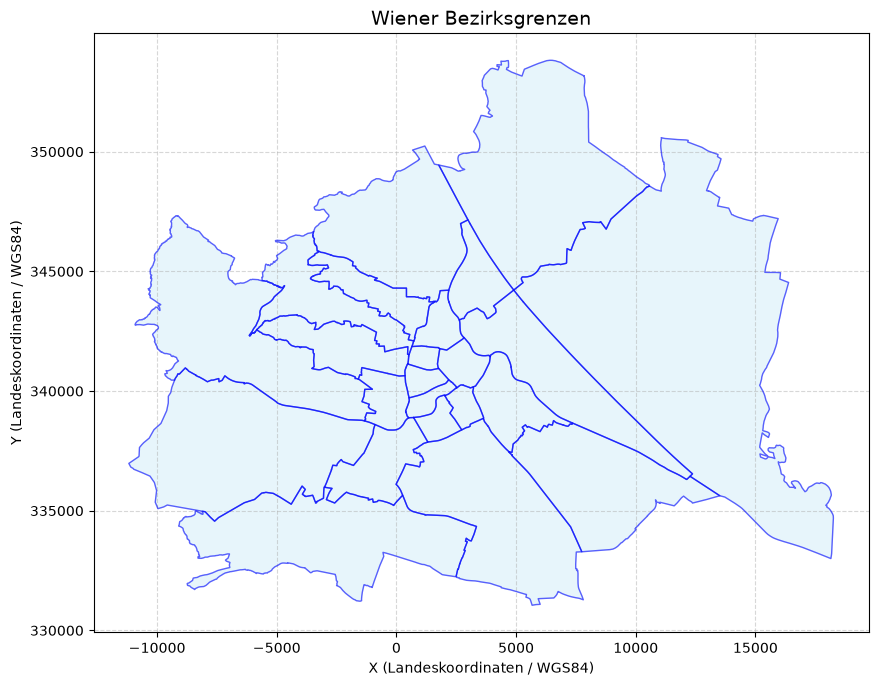

In [ ]:
import json
import matplotlib.pyplot as plt
from pathlib import Path  # Falls noch nicht importiert

# Basis-Pfad
BASE = Path.cwd().parent
EXTERNAL = BASE / "data" / "external"
bezirke_file = EXTERNAL / "bezirksgrenzen.json"

if bezirke_file.exists():
    bezirke = json.loads(bezirke_file.read_text(encoding="utf-8"))["features"]
    
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Durchlaufe alle Bezirke im GeoJSON
    for b in bezirke:
        geometry = b["geometry"]
        geom_type = geometry["type"]
        coords = geometry["coordinates"]
        name = b["properties"].get(
            "NAME", "Bezirk"
        )  # Bezirksname (je nach JSON-Struktur)

        if geom_type == "Polygon":
            # Ein einfaches Polygon (äußere Ringe)
            for ring in coords:
                x = [p[0] for p in ring]
                y = [p[1] for p in ring]
                ax.plot(x, y, color="blue", alpha=0.6, linewidth=1)
                ax.fill(x, y, color="skyblue", alpha=0.2)

        elif geom_type == "MultiPolygon":
            # MultiPolygon
            for polygon in coords:
                for ring in polygon:
                    x = [p[0] for p in ring]
                    y = [p[1] for p in ring]
                    ax.plot(x, y, color="blue", alpha=0.6, linewidth=1)
                    ax.fill(x, y, color="skyblue", alpha=0.2)

    ax.set_title("Wiener Bezirksgrenzen", fontsize=14)
    ax.set_xlabel("X (Landeskoordinaten / WGS84)")
    ax.set_ylabel("Y (Landeskoordinaten / WGS84)")
    ax.set_aspect("equal")  # Verhindert, dass die Karte verzerrt wird
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()
else:
    print(f"{bezirke_file} nicht gefunden")

**Bezirksgrenzen und Haltestellen visualisieren:**

-Note: Da die Haltestellen die gesamte VOR-Region abdecken, werden Haltestellen außerhalb der Wiener Stadtgrenze entfernt

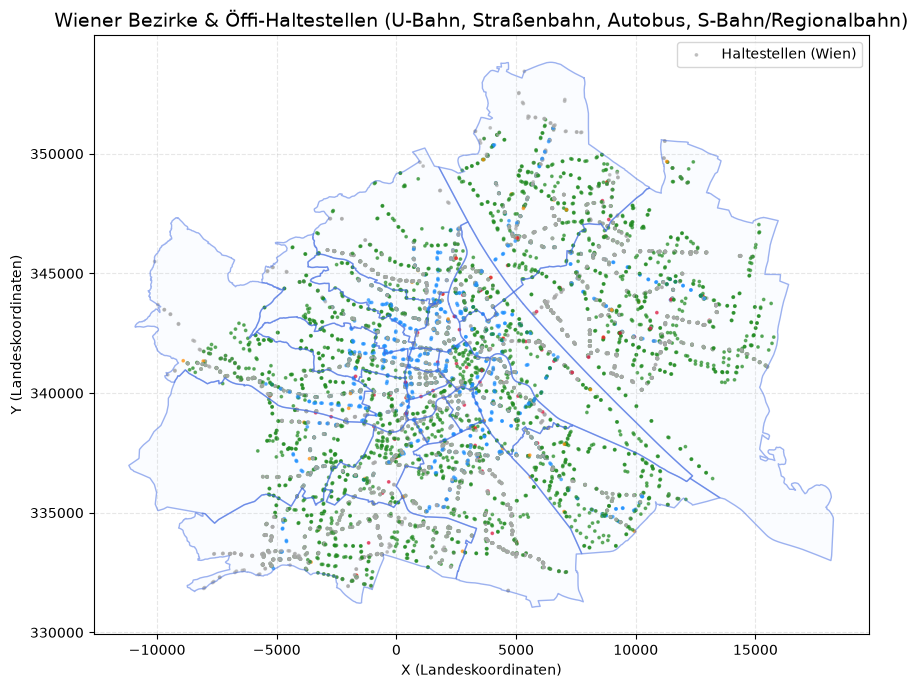

In [22]:
import json
import matplotlib.pyplot as plt
from pathlib import Path
from pyproj import Transformer
from shapely.geometry import shape, Point
from shapely.ops import unary_union

# Basis-Pfade
BASE = Path.cwd().parent
EXTERNAL = BASE / "data" / "external"

bezirke_file = EXTERNAL / "bezirksgrenzen.json"
stops_file = EXTERNAL / "haltestellen.json"

fig, ax = plt.subplots(figsize=(10, 10))

# 1. LAYER: Bezirksgrenzen laden und zu einer Stadtgrenze vereinen
vienna_poly = None
if bezirke_file.exists():
    bezirke = json.loads(bezirke_file.read_text(encoding="utf-8"))["features"]
    
    # Alle Bezirke zu einem großen Polygon-Objekt verschmelzen
    polys = [shape(b["geometry"]) for b in bezirke]
    vienna_poly = unary_union(polys)
    
    # Bezirke einzeichnen
    for b in bezirke:
        geometry = b["geometry"]
        geom_type = geometry["type"]
        coords = geometry["coordinates"]

        if geom_type == "Polygon":
            for ring in coords:
                x = [p[0] for p in ring]
                y = [p[1] for p in ring]
                ax.plot(x, y, color="#4169E1", alpha=0.5, linewidth=1)
                ax.fill(x, y, color="#F0F8FF", alpha=0.3)
        elif geom_type == "MultiPolygon":
            for polygon in coords:
                for ring in polygon:
                    x = [p[0] for p in ring]
                    y = [p[1] for p in ring]
                    ax.plot(x, y, color="#4169E1", alpha=0.5, linewidth=1)
                    ax.fill(x, y, color="#F0F8FF", alpha=0.3)

# 2. LAYER: Haltestellen transformieren und auf Wien filtern
if stops_file.exists() and vienna_poly is not None:
    stops = json.loads(stops_file.read_text(encoding="utf-8"))["features"]
    
    transformer = Transformer.from_crs("EPSG:4326", "EPSG:31256", always_xy=True)
    
    stop_x, stop_y, stop_colors = [], [], []
    
    color_map = {
        4: "#DC143C", # U-Bahn
        1: "#1E90FF", # Straßenbahn
        2: "#228B22", # Autobus
        5: "#FF8C00",  # S-Bahn
        6: "#8A2BE2"  # Badner Bahn
    }
    
    for f in stops:
        props = f["properties"]
        geom = f["geometry"]
        if geom and geom["type"] == "Point":
            lon, lat = geom["coordinates"]
            x_proj, y_proj = transformer.transform(lon, lat)
            point = Point(x_proj, y_proj)
            
            # ✨ Nur behalten, wenn der Punkt innerhalb von Wien liegt!
            if vienna_poly.contains(point):
                lt = props.get("LTYP")
                stop_x.append(x_proj)
                stop_y.append(y_proj)
                stop_colors.append(color_map.get(lt, "#A9A9A9"))

    ax.scatter(stop_x, stop_y, c=stop_colors, s=3, alpha=0.6, label="Haltestellen (Wien)")

ax.set_title("Wiener Bezirke & Öffi-Haltestellen (U-Bahn, Straßenbahn, Autobus, S-Bahn/Regionalbahn)", fontsize=14)
ax.set_xlabel("X (Landeskoordinaten)")
ax.set_ylabel("Y (Landeskoordinaten)")
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

**Ergänzen der Willhaben und ImmoScout24 anzeigen:**

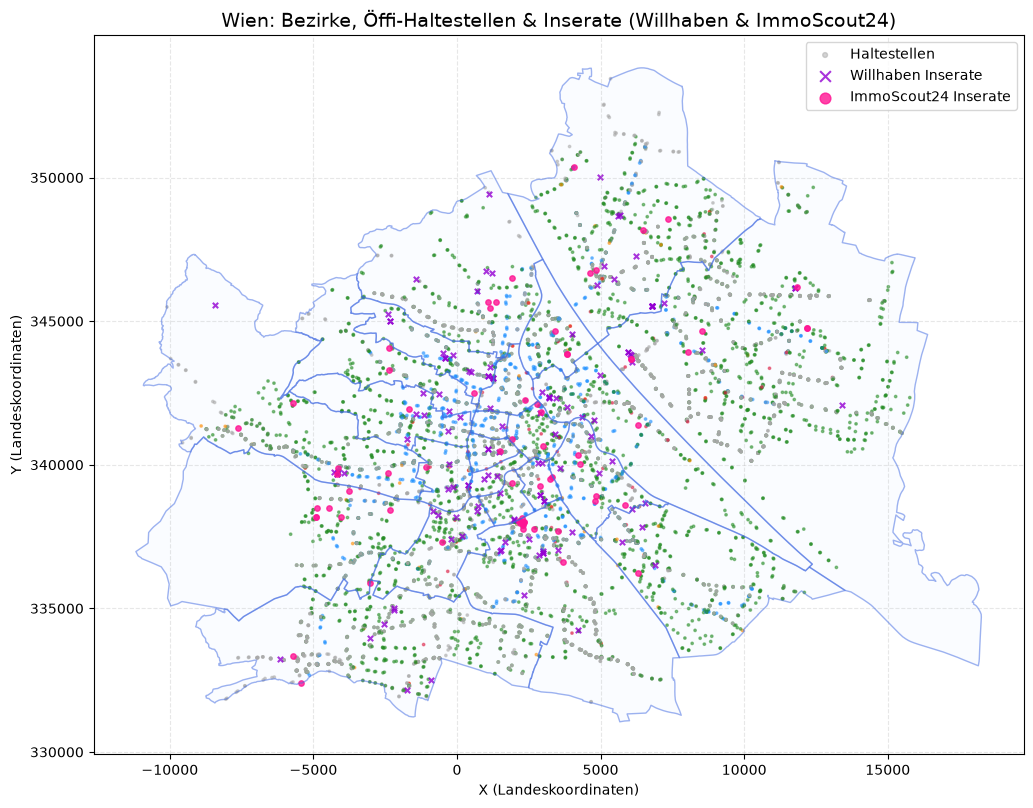

In [23]:
import json
import matplotlib.pyplot as plt
from pathlib import Path
from pyproj import Transformer
from shapely.geometry import shape, Point
from shapely.ops import unary_union

# Basis-Pfade
BASE = Path.cwd().parent
EXTERNAL = BASE / "data" / "external"

bezirke_file = EXTERNAL / "bezirksgrenzen.json"
stops_file = EXTERNAL / "haltestellen.json"

fig, ax = plt.subplots(figsize=(12, 12))

# Transformer für Koordinaten (WGS84 -> Wiener Landeskoordinaten EPSG:31256)
transformer = Transformer.from_crs("EPSG:4326", "EPSG:31256", always_xy=True)

# 1. LAYER: Bezirksgrenzen laden und zu einer Stadtgrenze vereinen
vienna_poly = None
if bezirke_file.exists():
    bezirke = json.loads(bezirke_file.read_text(encoding="utf-8"))["features"]
    
    polys = [shape(b["geometry"]) for b in bezirke]
    vienna_poly = unary_union(polys)
    
    for b in bezirke:
        geometry = b["geometry"]
        geom_type = geometry["type"]
        coords = geometry["coordinates"]

        if geom_type == "Polygon":
            for ring in coords:
                x = [p[0] for p in ring]
                y = [p[1] for p in ring]
                ax.plot(x, y, color="#4169E1", alpha=0.5, linewidth=1)
                ax.fill(x, y, color="#F0F8FF", alpha=0.3)
        elif geom_type == "MultiPolygon":
            for polygon in coords:
                for ring in polygon:
                    x = [p[0] for p in ring]
                    y = [p[1] for p in ring]
                    ax.plot(x, y, color="#4169E1", alpha=0.5, linewidth=1)
                    ax.fill(x, y, color="#F0F8FF", alpha=0.3)

# 2. LAYER: Haltestellen transformieren und auf Wien filtern
if stops_file.exists() and vienna_poly is not None:
    stops = json.loads(stops_file.read_text(encoding="utf-8"))["features"]
    
    stop_x, stop_y, stop_colors = [], [], []
    color_map = {
        4: "#DC143C", # U-Bahn
        1: "#1E90FF", # Straßenbahn
        2: "#228B22", # Autobus
        5: "#FF8C00", # S-Bahn
        6: "#8A2BE2"  # Badner Bahn
    }
    
    for f in stops:
        props = f["properties"]
        geom = f["geometry"]
        if geom and geom["type"] == "Point":
            lon, lat = geom["coordinates"]
            x_proj, y_proj = transformer.transform(lon, lat)
            point = Point(x_proj, y_proj)
            
            if vienna_poly.contains(point):
                lt = props.get("LTYP")
                stop_x.append(x_proj)
                stop_y.append(y_proj)
                stop_colors.append(color_map.get(lt, "#A9A9A9"))

    ax.scatter(stop_x, stop_y, c=stop_colors, s=3, alpha=0.5, label="Haltestellen")

# 3. LAYER: Inserate (Willhaben & ImmoScout24) einzeichnen
if vienna_poly is not None:
    # A) Willhaben Inserate (Koordinatenformat: "lat,lon" als String)
    if 'willhaben' in locals() and willhaben:
        wh_x, wh_y = [], []
        for r in willhaben:
            coords_str = r.get("coordinates")
            if coords_str and isinstance(coords_str, str) and "," in coords_str:
                try:
                    lat_s, lon_s = map(float, coords_str.split(","))
                    x_p, y_p = transformer.transform(lon_s, lat_s)
                    pt = Point(x_p, y_p)
                    if vienna_poly.contains(pt):
                        wh_x.append(x_p)
                        wh_y.append(y_p)
                except ValueError:
                    continue
        ax.scatter(wh_x, wh_y, c="#9400D3", s=15, marker="x", alpha=0.8, label="Willhaben Inserate")

    # B) ImmoScout24 Inserate (Koordinatenformat: Dictionary mit {"lat": ..., "lon": ...})
    if 'immoscout' in locals() and immoscout:
        im_x, im_y = [], []
        for r in immoscout:
            loc = r.get("location")
            if loc and isinstance(loc, dict) and "lat" in loc and "lon" in loc:
                try:
                    lat_s = float(loc["lat"])
                    lon_s = float(loc["lon"])
                    x_p, y_p = transformer.transform(lon_s, lat_s)
                    pt = Point(x_p, y_p)
                    if vienna_poly.contains(pt):
                        im_x.append(x_p)
                        im_y.append(y_p)
                except (ValueError, TypeError):
                    continue
        ax.scatter(im_x, im_y, c="#FF1493", s=15, marker="o", alpha=0.8, label="ImmoScout24 Inserate")

ax.set_title("Wien: Bezirke, Öffi-Haltestellen & Inserate (Willhaben & ImmoScout24)", fontsize=14)
ax.set_xlabel("X (Landeskoordinaten)")
ax.set_ylabel("Y (Landeskoordinaten)")
ax.set_aspect("equal")
ax.legend(loc="upper right", markerscale=2)
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()